## Skew-T and emagram diagrams

Besides the tephigram, earthkit-plots provides two other thermodynamic
diagrams: the skew-T log-p diagram (`SkewT`) and the emagram (`Emagram`).

The three diagrams differ only in how temperature and pressure are placed on
the page, so earthkit-plots gives them the same interface: the same methods,
with the same arguments and the same defaults. Code written for one diagram
works for the others by changing the class name.

| Diagram | Isobars | Isotherms | Default temperature range | Default pressure range |
|---|---|---|---|---|
| `Tephigram` | gently curved | at 45° to the dry adiabats | -60 to 60 °C | 1050 to 50 hPa |
| `SkewT` | horizontal, log-pressure scale | skewed at 45° | -40 to 50 °C | 1050 to 100 hPa |
| `Emagram` | horizontal, log-pressure scale | vertical | -80 to 40 °C | 1050 to 100 hPa |

This notebook uses the sounding of the
[Introduction to tephigrams](thermodynamic-tephigram.ipynb).

In [1]:
import earthkit.plots as ekp

In [2]:
# Pressure levels (hPa) of the temperature and dewpoint profiles
pressure = [
    977, 899, 849, 823, 810, 802, 771, 720, 693, 604, 587, 567, 559, 539, 505,
    492, 461, 453, 447, 433, 424, 402, 398, 383, 312, 297, 273, 264, 252, 215,
    208, 182, 175, 158, 155, 153, 149, 145, 142, 140, 130, 121, 109, 104,
]

# Temperature (°C)
temperature = [
    25.8, 18.8, 15.0, 14.0, 15.4, 15.8, 14.4, 9.6, 7.0, -2.5, -4.5, -5.3, -5.5,
    -8.1, -10.5, -12.1, -16.1, -17.1, -18.1, -19.7, -20.5, -23.9, -23.9, -25.7,
    -37.3, -39.7, -44.1, -45.9, -48.3, -55.9, -57.7, -62.3, -66.1, -67.9, -65.7,
    -65.7, -64.1, -64.5, -64.3, -63.5, -64.3, -66.7, -67.1, -68.3,
]

# Dewpoint (°C)
dewpoint = [
    10.8, 8.8, 6.0, 3.0, -20.6, -27.2, -23.6, -25.4, -12.0, -17.5, -14.5, -31.3,
    -32.5, -35.1, -45.5, -42.1, -30.1, -24.1, -23.1, -27.7, -38.5, -42.9, -57.9,
    -57.7, -67.3, -51.7, -55.1, -53.9, -59.3, -65.9, -71.7, -72.3, -76.1, -80.9,
    -81.7, -82.7, -85.1, -89.5, -93.3, -93.5, -94.3, -95.7, -96.1, -97.3,
]

# Wind components (m/s) on their own pressure levels (hPa)
wind_pressure = [989, 925, 850, 700, 500, 400, 300, 250]
u = [-3.856726, -4.588612, 1.91013, -2.871835e-08, 11.27631, 13.59462, 19.92389, 21.66577]
v = [4.596267, 6.553216, 10.83289, 8, 4.104242, 6.339274, 1.743115, 3.82026]

### Skew-T log-p diagrams

The skew-T is widely used in operational forecasting. The pressure axis is
logarithmic and the isotherms are skewed to the right, which separates the
temperature and dewpoint profiles and makes the lapse rates easier to compare
with the dry and saturated adiabats.

The profiles are plotted exactly as on a tephigram.

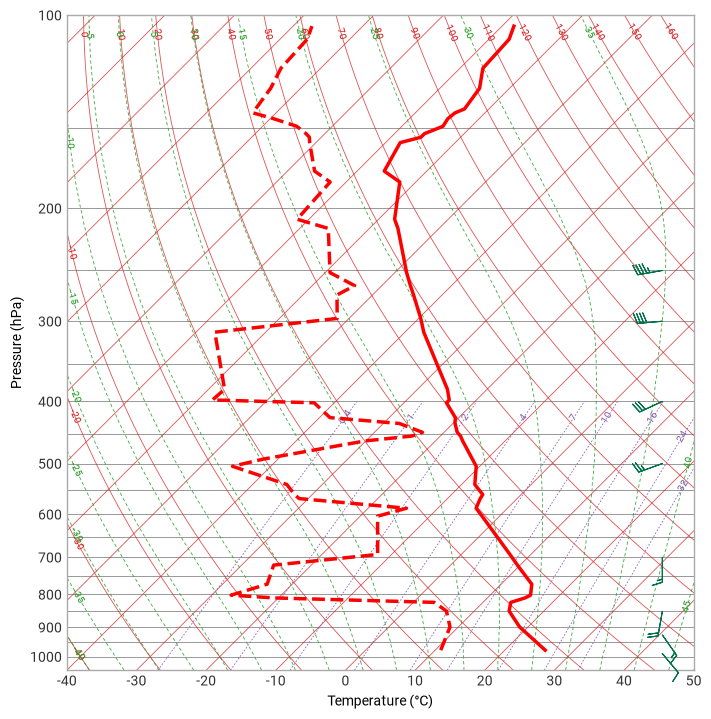

In [3]:
skewt = ekp.SkewT()

skewt.temperature(temperature, p=pressure, color="red", linewidth=2.5)
skewt.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
skewt.wind(u, v, p=wind_pressure, color="#00734d", position=0.95)

skewt.show()

The angle of the isotherms is set with `skew` (degrees from the horizontal,
45 by default). It is the only argument specific to the skew-T.

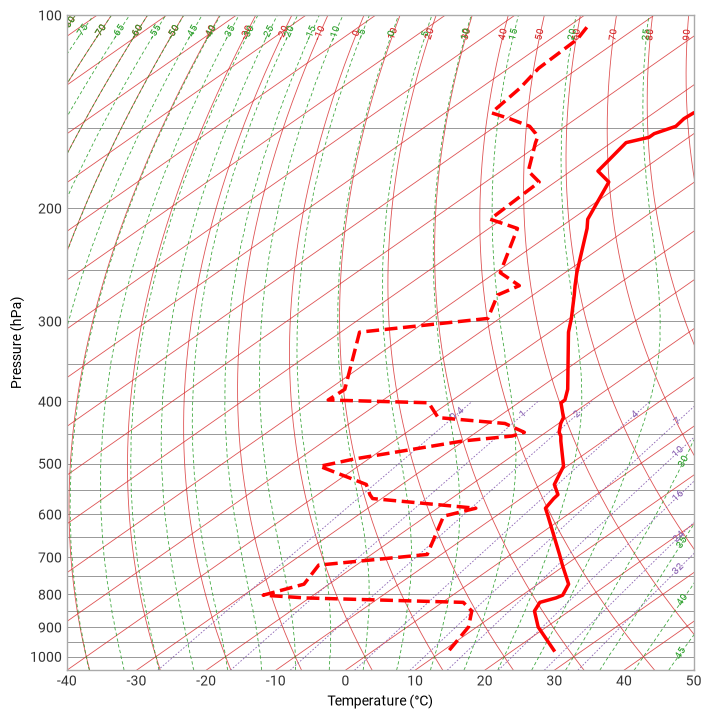

In [4]:
skewt = ekp.SkewT(skew=35)

skewt.temperature(temperature, p=pressure, color="red", linewidth=2.5)
skewt.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)

skewt.show()

### Emagrams

The emagram is the simplest of the three: temperature on a linear horizontal
axis against the logarithm of pressure, so the isotherms are vertical. Again,
only the class changes.

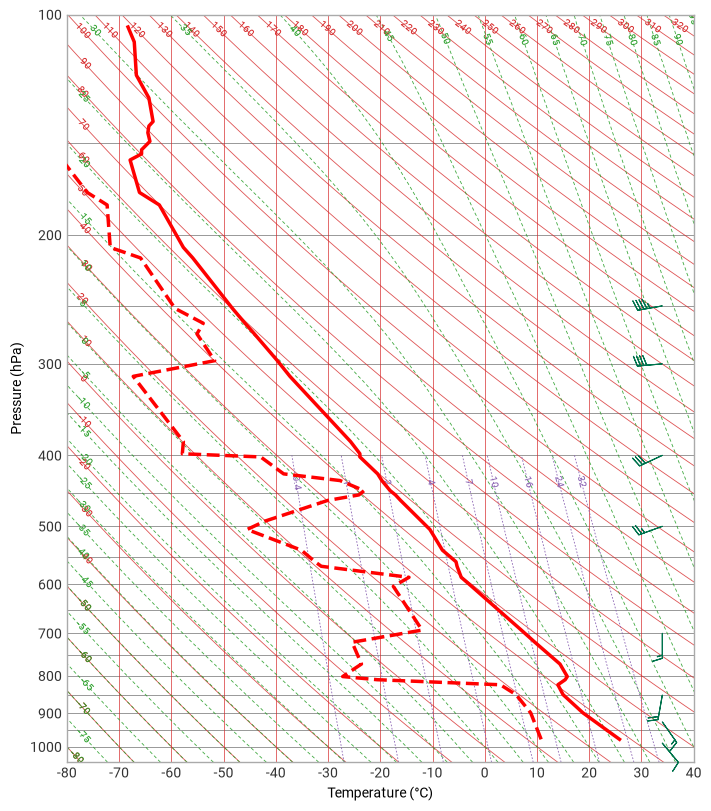

In [5]:
emagram = ekp.Emagram()

emagram.temperature(temperature, p=pressure, color="red", linewidth=2.5)
emagram.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
emagram.wind(u, v, p=wind_pressure, color="#00734d", position=0.95)

emagram.show()

### One function for every diagram

Because the interface is shared, a function that plots a sounding can take the
diagram class as an argument. Everything below (the extent, the background
lines, the side panel and the title) works the same way on each diagram.

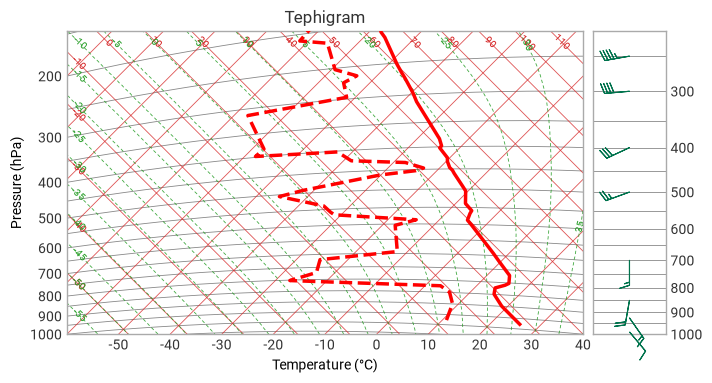

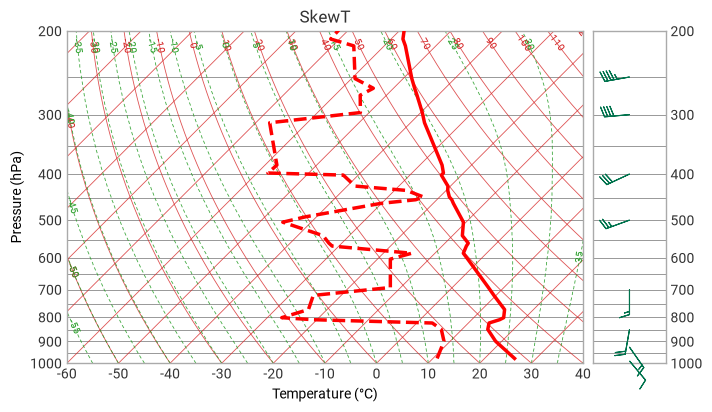

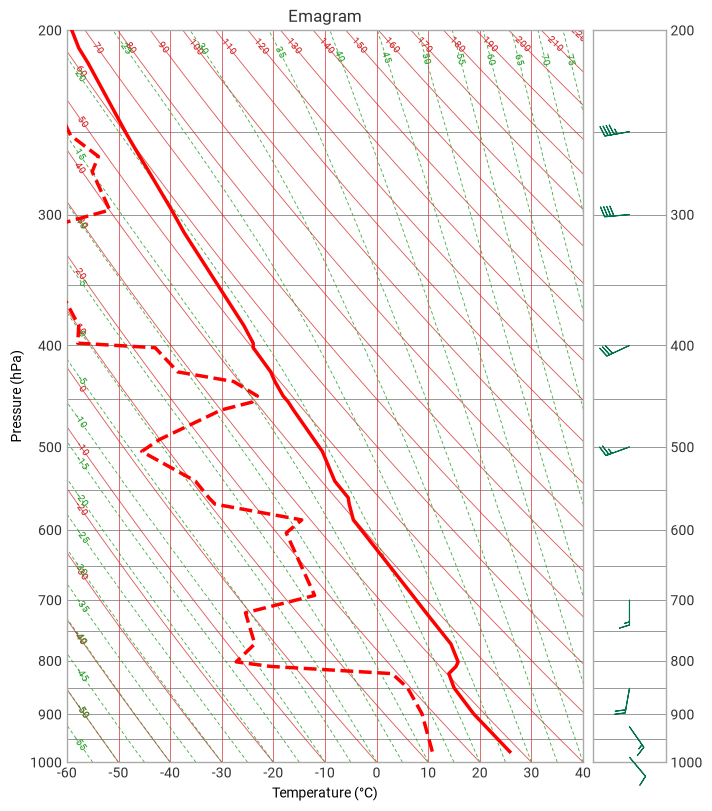

In [6]:
def plot_sounding(diagram_class):
    diagram = diagram_class(temperature_range=(-60, 40), pressure_range=(1000, 200))
    diagram.grid(mixing_ratios=False)

    diagram.temperature(temperature, p=pressure, color="red", linewidth=2.5)
    diagram.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
    diagram.wind(u, v, p=wind_pressure, color="#00734d", panel=True)

    diagram.title(diagram_class.__name__)
    return diagram


for diagram_class in (ekp.Tephigram, ekp.SkewT, ekp.Emagram):
    plot_sounding(diagram_class).show()

### What's next?

The thermodynamic diagrams in the gallery show more: profiles from BUFR
soundings, ensemble spread with side panels, and parcel paths with CAPE and
CIN. They are drawn on tephigrams and skew-Ts, but each works on any of the
three diagrams.